         network: XJ
         station: TRANB
        location: 
         channel: HHZ
       starttime: 2004-12-26T00:58:53.399000Z
         endtime: 2004-12-26T01:15:33.399000Z
   sampling_rate: 100.0
           delta: 0.01
            npts: 100001
           calib: 2353540000.0
         _format: SAC
             sac: AttribDict({'delta': np.float32(0.01), 'depmin': np.float32(-3101.7793), 'depmax': np.float32(2728.1526), 'scale': np.float32(2353540000.0), 'b': np.float32(-7.8231096e-08), 'e': np.float32(1000.0), 'o': np.float32(0.0), 'internal0': np.float32(2.0), 'stla': np.float32(-46.63544), 'stlo': np.float32(-72.83952), 'stel': np.float32(355.0), 'stdp': np.float32(0.0), 'depmen': np.float32(-290.02667), 'cmpaz': np.float32(0.0), 'cmpinc': np.float32(0.0), 'nzyear': np.int32(2004), 'nzjday': np.int32(361), 'nzhour': np.int32(0), 'nzmin': np.int32(58), 'nzsec': np.int32(53), 'nzmsec': np.int32(399), 'nvhdr': np.int32(6), 'norid': np.int32(0), 'nevid': np.int32(0), 'npts': np.int32

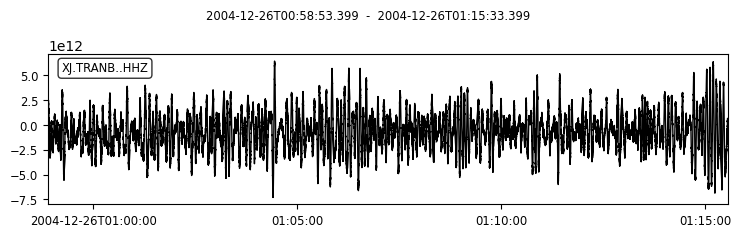

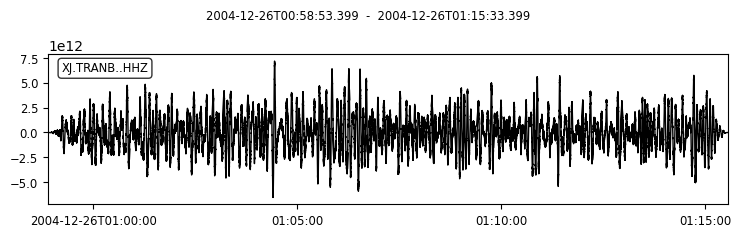

In [2]:
from obspy import read

tr = read("ruido_TRANB.HHZ")[0]
print(tr.stats)
out1=tr.plot()
tr_filtered = tr.copy()
tr_filtered.detrend("demean"); tr_filtered.detrend("linear"); tr_filtered.taper(0.05, type="cosine")
out2=tr_filtered.plot()

In [6]:
from obspy.io.sac.sacpz import attach_paz
attach_paz(tr, paz_file="3T.pz.txt")
paz = tr.stats.paz
tr_a = tr.copy().simulate(paz_remove=paz,pre_filt=(0.005, 0.01, 45, 49)).differentiate().differentiate()

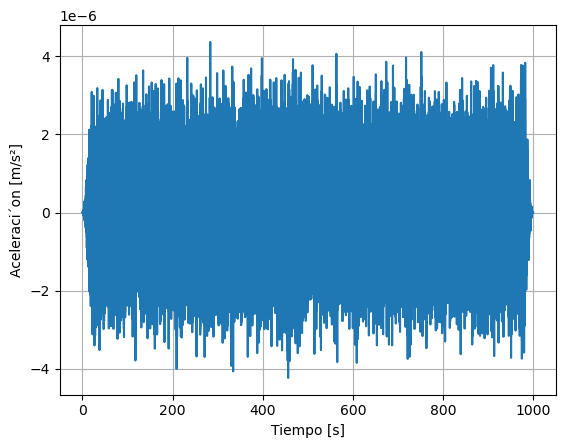

In [7]:
import matplotlib.pyplot as plt
t = tr_a.times()
plt.plot(t, tr_a.data)
plt.xlabel("Tiempo [s]"); plt.ylabel("Aceleraci´on [m/s²]"); plt.grid(True)
plt.show()

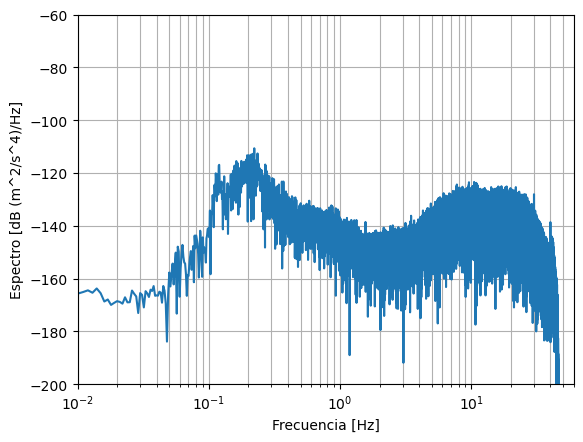

In [9]:
import numpy as np
X = np.fft.rfft(tr_a.data)
N = tr_a.stats.npts
Fs = 1.0 / tr_a.stats.delta
P = np.abs(X)**2 / (Fs * N)
P[1:-1] *= 2.0 #don't multiply first (0Hz) and last (Nyquist) spectral bin by 2
S_db = 10.0 * np.log10(np.maximum(P, np.finfo(float).tiny))
f = np.fft.rfftfreq(tr_a.stats.npts, d=tr_a.stats.delta)
plt.semilogx(f[1:], S_db[1:]) #remove first point (0Hz)
plt.xlim(0.01, 60)
plt.ylim(-200,-60)
plt.xlabel("Frecuencia [Hz]")
plt.ylabel("Espectro [dB (m^2/s^4)/Hz]")
plt.grid(True, which="both")
plt.show()

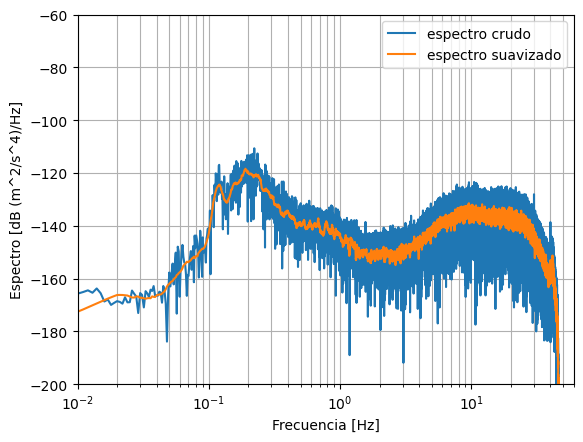

In [12]:
from scipy.signal import savgol_filter
S_db_sm = savgol_filter(S_db, window_length=41, polyorder=2, mode="interp")
plt.semilogx(f[1:], S_db[1:], label="espectro crudo")
plt.semilogx(f[1:], S_db_sm[1:], label="espectro suavizado")
plt.xlim(0.01, 60)
plt.ylim(-200,-60)
plt.grid(True, which="both")
plt.xlabel("Frecuencia [Hz]")
plt.ylabel("Espectro [dB (m^2/s^4)/Hz]")
plt.legend()
plt.show()

[1.00000e+05 9.86279e+04 9.72747e+04 ... 1.02802e-01 1.01391e-01
 1.00000e-01] [-103.13   -103.4225 -103.715  ... -167.932  -167.966  -168.    ]


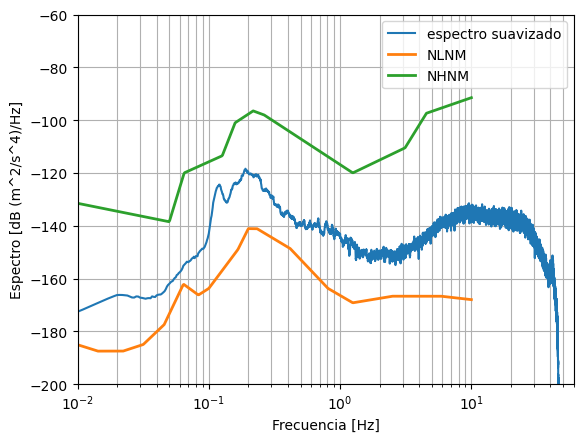

In [13]:
from obspy.signal.spectral_estimation import get_nlnm, get_nhnm
per_nlnm, nlnm_db = get_nlnm() #periodos, decibelios nlnm
per_nhnm, nhnm_db = get_nhnm()
print(per_nlnm,nlnm_db) #visualizar los periodos y valores db
f_nlnm = 1.0 / per_nlnm #pasar de periodo a frecuencia
f_nhnm = 1.0 / per_nhnm
plt.semilogx(f[1:], S_db_sm[1:], label="espectro suavizado")
plt.semilogx(f_nlnm, nlnm_db, lw=2, label="NLNM")
plt.semilogx(f_nlnm, nhnm_db, lw=2, label="NHNM")
plt.xlim(0.01, 60)
plt.ylim(-200,-60)
plt.grid(True, which="both")
plt.xlabel("Frecuencia [Hz]")
plt.ylabel("Espectro [dB (m^2/s^4)/Hz]")
plt.legend()
plt.show()


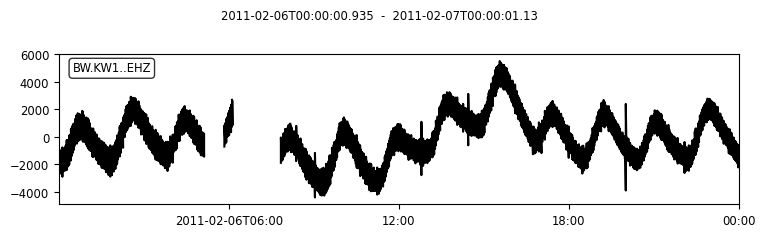

Source            Last Sample                 Next Sample                 Delta           Samples 
BW.KW1..EHZ       2011-02-06T05:07:21.115000Z 2011-02-06T05:50:15.079999Z 2573.959999     514792  
BW.KW1..EHZ       2011-02-06T06:07:21.514999Z 2011-02-06T07:49:55.940000Z 6154.420001     1230884 
Total: 2 gap(s) and 0 overlap(s)


In [14]:
from obspy import read
from obspy.signal import PPSD
from obspy import UTCDateTime
from obspy import read_inventory
st = read("https://examples.obspy.org/BW.KW1..EHZ.D.2011.037")
tr = st.select(id="BW.KW1..EHZ")[0]
st.plot()
st.print_gaps()

c:\Users\Kaito\miniconda3\envs\sismologia\lib\site-packages\obspy\clients\fdsn\routing\routing_client.py:68: ObsPyDeprecationWarning: IRIS is now EarthScope, please consider changing the 'routing_type' to 'earthscope-federator'.
  warnings.warn(msg, ObsPyDeprecationWarning)


number of psd segments: 47
number of psd segments: 93


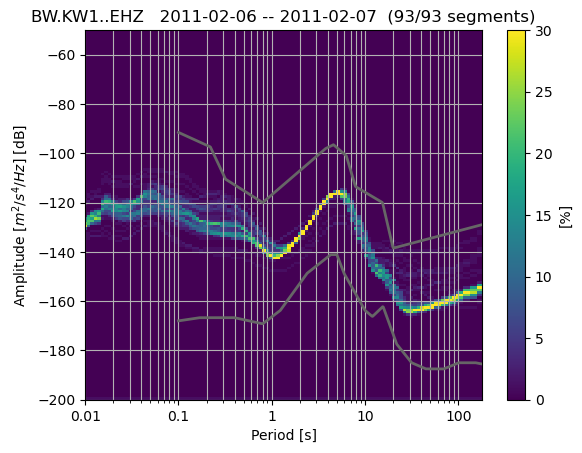

In [18]:
from obspy.clients.fdsn import Client
from obspy.clients.fdsn import RoutingClient
rc = RoutingClient("iris-federator") # routes across IRIS + EIDA
t0 = UTCDateTime("2011-02-06")
inv = rc.get_stations(network="BW", station="KW1", channel="EHZ",
starttime=t0, endtime=t0 + 86400, level="response")
inv.write("BW_KW1.xml", format="STATIONXML")

ppsd = PPSD(tr.stats, metadata=inv)
ppsd.add(st)
print("number of psd segments:", len(ppsd.times_processed))

st = read("https://examples.obspy.org/BW.KW1..EHZ.D.2011.038")
ppsd.add(st)
print("number of psd segments:", len(ppsd.times_processed))

ppsd.plot(show_coverage=False)
from obspy.imaging.cm import pqlx
ppsd.plot(show_coverage=False,cmap=pqlx,filename="ppsd.png")


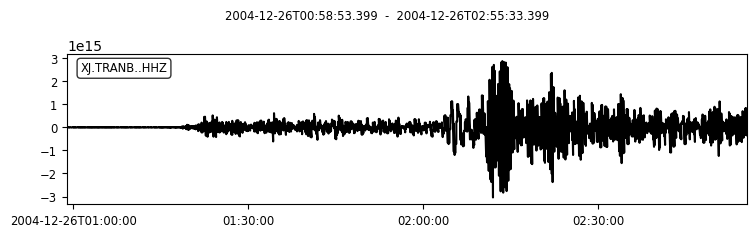

In [41]:
from obspy import read

tr = read("2004361005853_XJ_TRANB.HHZ")
out1=tr.plot()

Terremoto de 9.1Mw el 26 de diciembre de 2004, conocido como el Terremoto de Indonesia (Sumatra)

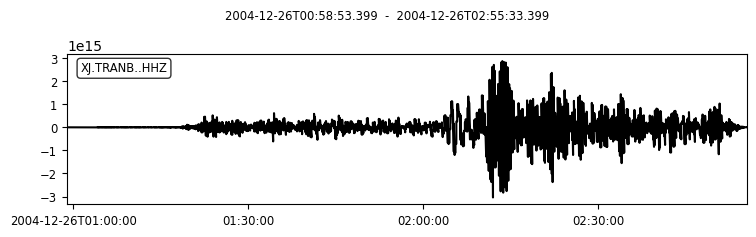

In [39]:
tr = read("2004361005853_XJ_TRANB.HHZ")
tr_filtered = tr.copy()
tr_filtered.detrend("demean"); tr_filtered.detrend("linear"); tr_filtered.taper(0.05, type="cosine")
out2=tr_filtered.plot()

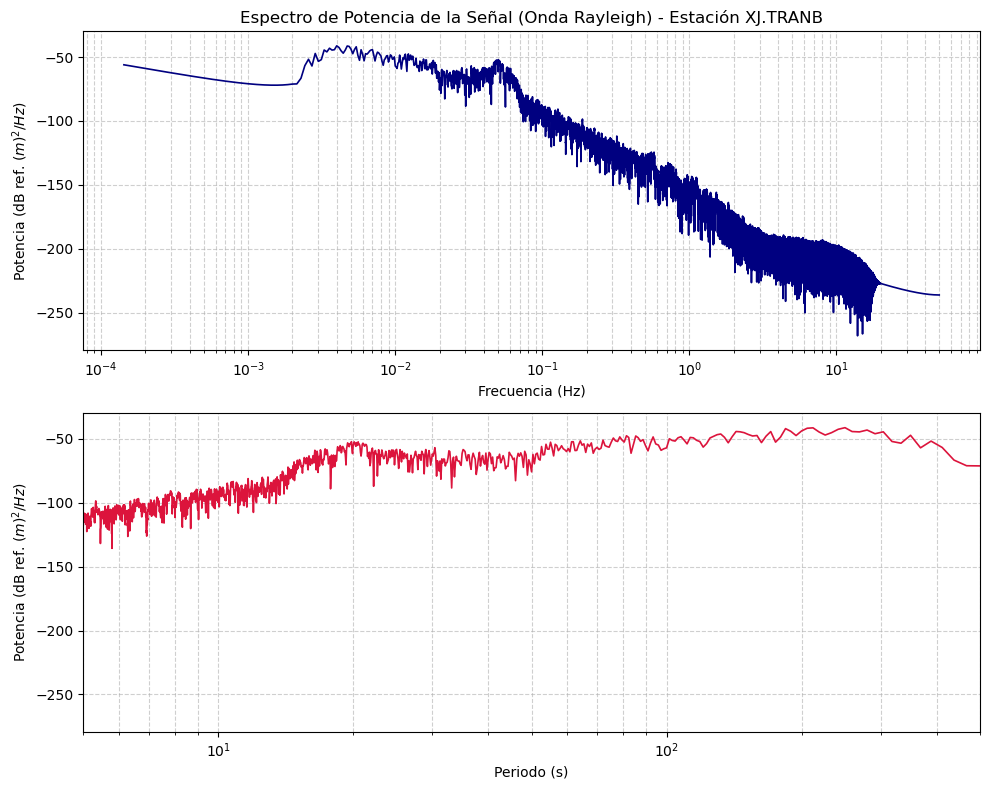

In [47]:
import numpy as np
import matplotlib.pyplot as plt
from obspy import read
from obspy.io.sac.sacpz import attach_paz

#1) Cargar el stream y extraer la traza de la señal
st = read("2004361005853_XJ_TRANB.HHZ")
tr = st[0].copy()

#2) Adjuntar los polos y ceros a la traza
attach_paz(tr, paz_file="3T.pz.txt")
paz = tr.stats.paz

#3) Simular la respuesta de la traza con los polos y ceros adjuntos, eliminando la respuesta del instrumento y aplicando un filtro previo
tr_disp = tr.copy().simulate(paz_remove=paz,pre_filt=(0.002, 0.005, 10, 20))

#4) Cálculo del espectro de potencia (FFT / PSD)
data = tr_disp.data #extraer los datos de la traza
N = tr_disp.stats.npts #número de puntos de la traza 
dt = tr_disp.stats.delta #intervalo de muestreo
Sr = tr_disp.stats.sampling_rate #frecuencia de muestreo

#4.1) Calcular la FFT de los datos
fft_values = np.fft.rfft(data) #calcular la FFT de los datos
freqs = np.fft.rfftfreq(N, dt) #calcular las frecuencias correspondientes a la FFT

#4.2) Densidad espectral de potencia (PSD) normalizada
# Potencia = |FFT|^2 / (npts * fs)
psd = (np.abs(fft_values) ** 2) / (N * Sr)

#4.3) Convertir a decibelios
psd_db = 10 * np.log10(psd)

# Periodo en segundos (T = 1 / f)
periodos = 1.0 / freqs[1:]
psd_db_periodos = psd_db[1:]

#5) Graficar los resultados
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 8))

# Subplot 1: Espectro vs Frecuencia
ax1.semilogx(freqs[1:], psd_db[1:], color="navy", lw=1.2)
ax1.set_title("Espectro de Potencia de la Señal (Onda Rayleigh) - Estación XJ.TRANB")
ax1.set_xlabel("Frecuencia (Hz)")
ax1.set_ylabel("Potencia (dB ref. $(m)^2/Hz$)")
ax1.grid(True, which="both", ls="--", alpha=0.6)

# Subplot 2: Espectro vs Periodo (convencional para ondas superficiales)
ax2.semilogx(periodos, psd_db_periodos, color="crimson", lw=1.2)
ax2.set_xlabel("Periodo (s)")
ax2.set_ylabel("Potencia (dB ref. $(m)^2/Hz$)")
ax2.set_xlim(5, 500)  # Rango representativo de ondas de superficie teleseísmicas
ax2.grid(True, which="both", ls="--", alpha=0.6)

plt.tight_layout()
plt.show()

Peak de potencia (en dB) de la onda Rayleigh a los 20s de periodo, esto en frecuencia corresponde a 0.05Hz (peak local en color azul).